# Load ICON data, quickplot as healpix, calculate input variables, resample, plot resampled


- startet from ````/work/bb1376/user/fabian/analysis/2024-03_warmworld-hackathon/nbooks/03-Segment-Regridded-ICON-Data````
- and https://tobac.readthedocs.io/en/latest/examples/Example_ICON_MCS_tracking/Example_ICON_MCS_tracking.html


todo
- check what variables to use for creating a equivalent to IWP from CCIC
- precip rate conversion check
- resample to regular grid
- ggf
    - tropcial belt plot
  

In [1]:
import intake
import cartopy.crs as ccrs
import cartopy.feature as cf

import healpy as hp

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

import pandas as pd

import scipy.ndimage
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# load data

zoom level selection ran into error
print(intake.__version__)
- => MA_numpy23 has intake version 2.0.9
- => 1 python3 levante 0.6.8
- => MA_numpy23 => pip install "intake==0.6.6" "intake-esm==2022.9.18" "intake-xarray==0.6.1" 

In [3]:
# VERSION A 
cat = intake.open_catalog("https://data.nextgems-h2020.eu/catalog.yaml")

# # look at existing parameter
# import pandas as pd
# print(pd.DataFrame(cat.ICON.ngc4008.describe()["user_parameters"]))


exp_id = "ngc4008"
zoom = 9
dataset = cat.ICON[exp_id](zoom = zoom, time = 'PT3H', chunks = 'auto').to_dask()
dataset = dataset.chunk()
display(dataset)


# # ALTERNATIVE VERSION B WITH FUNCTION
# import sys
# sys.path.append("../tools/")
# import handle_ICON_data as ic

# zoom = 8
# dataset = ic.open_ngc4008(zoom = zoom) 
# dataset

<xarray.Dataset> Size: 849TB
Dimensions:                              (time: 87664, depth_half: 73,
                                          cell: 3145728, level_full: 90,
                                          soil_depth_water_level: 5,
                                          depth_full: 72,
                                          soil_depth_energy_level: 5,
                                          level_half: 91, crs: 1)
Coordinates:
  * time                                 (time) datetime64[ns] 701kB 2020-01-...
  * depth_half                           (depth_half) float32 292B 0.0 ... 5....
    zg                                   (level_full, cell) float32 1GB dask.array<chunksize=(90, 360448), meta=np.ndarray>
  * level_full                           (level_full) int32 360B 1 2 3 ... 89 90
  * soil_depth_water_level               (soil_depth_water_level) float32 20B ...
  * depth_full                           (depth_full) float32 288B 1.0 ... 5....
  * soil_depth_energy_level              (soil_depth_energy_level) float32 20B ...
  * crs                                  (crs) float32 4B nan
Dimensions without coordinates: cell, level_half
Data variables: (12/85)
    A_tracer_v_to                        (time, depth_half, cell) float32 81TB dask.array<chunksize=(32, 30, 32768), meta=np.ndarray>
    Qbot                                 (time, cell) float32 1TB dask.array<chunksize=(496, 32768), meta=np.ndarray>
    Qtop                                 (time, cell) float32 1TB dask.array<chunksize=(496, 32768), meta=np.ndarray>
    Wind_Speed_10m                       (time, cell) float32 1TB dask.array<chunksize=(496, 32768), meta=np.ndarray>
    atmos_fluxes_FrshFlux_Evaporation    (time, cell) float32 1TB dask.array<chunksize=(496, 32768), meta=np.ndarray>
    atmos_fluxes_FrshFlux_Precipitation  (time, cell) float32 1TB dask.array<chunksize=(496, 32768), meta=np.ndarray>
    ...                                   ...
    v_vint                               (time, cell) float32 1TB dask.array<chunksize=(496, 32768), meta=np.ndarray>
    va                                   (time, level_full, cell) float32 99TB dask.array<chunksize=(32, 30, 32768), meta=np.ndarray>
    vas                                  (time, cell) float32 1TB dask.array<chunksize=(496, 32768), meta=np.ndarray>
    w                                    (time, depth_half, cell) float32 81TB dask.array<chunksize=(32, 30, 32768), meta=np.ndarray>
    zghalf                               (level_half, cell) float32 1GB dask.array<chunksize=(91, 360448), meta=np.ndarray>
    zos                                  (time, cell) float32 1TB dask.array<chunksize=(496, 32768), meta=np.ndarray>

In [16]:
dataset["clivi"]

<xarray.DataArray 'clivi' (time: 1, cell: 3145728)> Size: 13MB
dask.array<getitem, shape=(1, 3145728), dtype=float32, chunksize=(1, 32768), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 8B 2020-06-06T18:00:00
Dimensions without coordinates: cell
Attributes:
    cell_methods:  time: mean cell: mean
    component:     atmo
    grid_mapping:  crs
    long_name:     vertically integrated cloud ice
    units:         kg m-2
    vgrid:         atmosphere

Text(0.5, 1.0, 'OLR at zoom 9')

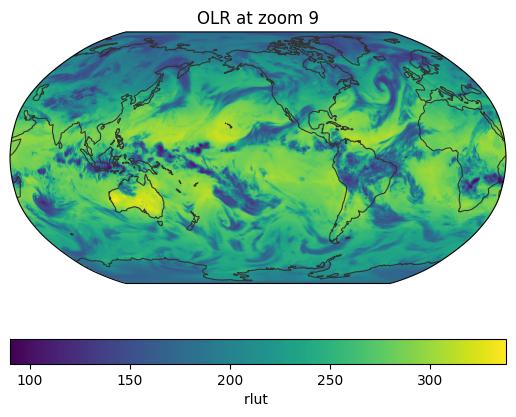

In [5]:
import healpix
import easygems.healpix as egh

img = egh.healpix_show(dataset.rlut.isel(time=0).values)
plt.colorbar(img, orientation="horizontal", label="rlut ")
plt.title(f"OLR at zoom {zoom}")

Text(0.5, 1.0, 'Precip at zoom 9')

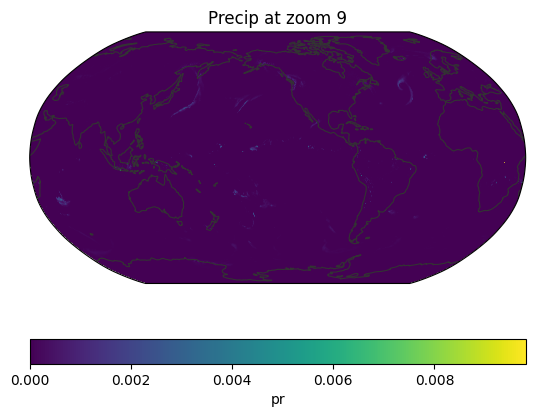

In [6]:
import healpix
import easygems.healpix as egh

img = egh.healpix_show(dataset.pr.isel(time=0).values)
plt.colorbar(img, orientation="horizontal", label="pr")
plt.title(f"Precip at zoom {zoom}")

# select date and variabels

In [7]:
for vname in dataset.data_vars:
    print(vname)
    try:
        print(' %s  in  %s' %  (dataset[vname].long_name, dataset[vname].units))
    except:
        pass
    print()

A_tracer_v_to
 sea water vertical diffusivity  in  m2 s-1

Qbot
 Conductive heat flux at ice-ocean interface  in  W/m^2

Qtop
 Energy flux available for surface melting  in  W/m^2

Wind_Speed_10m
 Wind Speed at 10m height  in  m/s

atmos_fluxes_FrshFlux_Evaporation

atmos_fluxes_FrshFlux_Precipitation

atmos_fluxes_FrshFlux_Runoff

atmos_fluxes_FrshFlux_SnowFall

atmos_fluxes_HeatFlux_Latent

atmos_fluxes_HeatFlux_LongWave

atmos_fluxes_HeatFlux_Sensible

atmos_fluxes_HeatFlux_ShortWave

atmos_fluxes_HeatFlux_Total

atmos_fluxes_stress_x

atmos_fluxes_stress_xw

atmos_fluxes_stress_y

atmos_fluxes_stress_yw

clivi
 vertically integrated cloud ice  in  kg m-2

cllvi
 vertically integrated cloud water  in  kg m-2

conc

dzghalf
 vertical extent of model full layer  in  m

heat_content_seaice

heat_content_snow

heat_content_total

hfls
 latent heat flux  in  W m-2

hfss
 sensible heat flux  in  W m-2

hi
 ice thickness  in  m

hs
 snow thickness  in  m

hydro_canopy_cond_limited_box

hyd

In [8]:
dataset["rlut"]


<xarray.DataArray 'rlut' (time: 87664, cell: 3145728)> Size: 1TB
dask.array<open_dataset-rlut, shape=(87664, 3145728), dtype=float32, chunksize=(496, 32768), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 701kB 2020-01-01T03:00:00 ... 2050-01-01
Dimensions without coordinates: cell
Attributes:
    cell_methods:   time: mean cell: mean
    component:      atmo
    grid_mapping:   crs
    long_name:      toa outgoing longwave radiation
    standard_name:  toa_outgoing_longwave_flux
    units:          W m-2
    vgrid:          toa

In [9]:
def select_time(dataset, date): 
    ds = dataset.sel(time = slice(date, date))
    return ds

def select_vars(dataset,vlist=["pr", "rlut", "tas", "qsvi","clivi","qgvi","crs"]):
    ds = dataset[vlist] 
    return ds
    
# select timestep
date = "2020-06-06-1800"
# select variables
vlist = ["pr", "rlut", "tas", "qsvi","clivi","qgvi","crs"]

dataset = select_time(dataset, date)
dataset = select_vars(dataset, vlist)

# for precip
# pr = precipitation flux  in  kg m-2 s-1

# for Tb (and T)
# rlut = toa outgoing longwave radiation  in  W m-2 (OLR)
# tas =  temperature in 2m  in  K 

# for iwp
# qsvi =  vertically integrated snow  in  kg m-2
# clivi  = vertically integrated cloud ice  in  kg m-2
# qgvi  =  vertically integrated graupel  in  kg m-2



dataset

<xarray.Dataset> Size: 75MB
Dimensions:  (time: 1, cell: 3145728, crs: 1)
Coordinates:
  * time     (time) datetime64[ns] 8B 2020-06-06T18:00:00
  * crs      (crs) float32 4B nan
Dimensions without coordinates: cell
Data variables:
    pr       (time, cell) float32 13MB dask.array<chunksize=(1, 32768), meta=np.ndarray>
    rlut     (time, cell) float32 13MB dask.array<chunksize=(1, 32768), meta=np.ndarray>
    tas      (time, cell) float32 13MB dask.array<chunksize=(1, 32768), meta=np.ndarray>
    qsvi     (time, cell) float32 13MB dask.array<chunksize=(1, 32768), meta=np.ndarray>
    clivi    (time, cell) float32 13MB dask.array<chunksize=(1, 32768), meta=np.ndarray>
    qgvi     (time, cell) float32 13MB dask.array<chunksize=(1, 32768), meta=np.ndarray>

# calculate variables

Obs: 
- Nasa Tb => manually calculate brightness temperature, (later histo matching with synsat from other timeperiod)
- IMERG => precip in mm/hr
    - for ICON: calc rain rate in mm/hr from precip flux
- CCIC => tiwp - kg m-2 ≥ 0 Vertically-integrated concentration of frozen hydrometeors
    - from ICON i use: vertically integrated cloud ice, graupel and snow

In [10]:
# precipitation
def add_precip_tot_rate_day(dataset):
    dataset['rain_tot_rate_day'] = 3600 * 24 * ( dataset['pr'] )  # unit convetion to mm day-1
    
    dataset['rain_tot_rate_day'].attrs['units'] = 'mm day-1'
    
    dataset['rain_tot_rate_day'].attrs['long_name'] = 'rain rate'
    dataset['rain_tot_rate_day'].attrs['short_name'] = 'rain rate'
    return dataset


def add_precip_tot_rate(dataset):
    dataset['rain_tot_rate'] = 3600 * ( dataset['pr'] )  # unit convetion to mm day-1
    
    dataset['rain_tot_rate'].attrs['units'] = 'mm h-1'
    
    dataset['rain_tot_rate'].attrs['long_name'] = 'rain rate'
    dataset['rain_tot_rate'].attrs['short_name'] = 'rain rate'
    return dataset

# frozen water path
def add_iwp(dataset):
    dataset['iwp'] = dataset['clivi'] + dataset['qsvi'] + dataset["qgvi"]
    
    dataset['iwp'].attrs['units'] = 'kg m-2'
    
    dataset['iwp'].attrs['long_name'] = 'Ice water path' # vertically integrated frozem water
    dataset['iwp'].attrs['short_name'] = 'IWP'
    return dataset


# Tb 
def get_tb(olr):
    """
    from https://tobac.readthedocs.io/en/latest/examples/Example_ICON_MCS_tracking/Example_ICON_MCS_tracking.html
    
    This function converts outgoing longwave radiation to brightness temperatures.
    11 micron brightness temperature (BT) 

    Args:
        olr(xr.DataArray or numpy array): 2D field of model output with OLR

    Returns:
        tb(xr.DataArray or numpy array): 2D field with estimated brightness temperatures
    """
    # constants
    aa = 1.228
    bb = -1.106e-3  # K−1
    # Planck constant
    sigma = 5.670374419e-8  # W⋅m−2⋅K−4

    # flux equivalent brightness temperature
    Tf = (abs(olr) / sigma) ** (1.0 / 4) # (Stefan boltzman orl = sigma T^4 (changed to T =..) 

    # this is a empirical quadratic relation
    #    => Satellite infrared channels (like 11 µm) do not measure total radiative flux.
    #    => They measure radiance at a specific wavelength.
    #    => I COULD ADAPT THESE USING THE SYNSAT IMAGES? 
    tb = (((aa**2 + 4 * bb * Tf) ** (1.0 / 2)) - aa) / (2 * bb)
    tb = Tf
    return tb

def add_tb_11(dataset):
    dataset["tb_11"] = get_tb(dataset["rlut"])
    
    dataset['tb_11'].attrs['units'] = 'K'
    
    dataset['tb_11'].attrs['long_name'] = 'estimated Tb at 11micronmeter'
    dataset['tb_11'].attrs['short_name'] = 'Tb'

    return dataset 

# add variables
def add_input_vars(dataset): 
    dataset = add_precip_tot_rate(dataset)
    dataset = add_iwp(dataset)
    dataset = add_tb_11(dataset)
    dataset = add_precip_tot_rate(dataset)
    return dataset

In [11]:
# Version A
dataset = add_input_vars(dataset)

# # Version B
# dataset = ic.add_input_vars(dataset)
# dataset

# Plotting 
https://easy.gems.dkrz.de/Processing/playing_with_triangles/tripcolor.html

In [12]:
def plot_worldmap(dataset, var, cmap = "viridis", norm = None):
    import healpix
    import easygems.healpix as egh
    
    plt.figure(figsize=(8,5))
    img = egh.healpix_show(dataset[var].isel(time=0).values, cmap = cmap, norm = norm)
    
    units = dataset[var].attrs.get("units", "")
    long_name = dataset[var].attrs.get("long_name", var)
    date = pd.to_datetime(dataset.time[0].values).strftime("%Y-%m-%d %H:%M")
    
    plt.colorbar(img, orientation="horizontal", label=f"{long_name} [{units}]", shrink = 0.9)
    plt.title(f"{long_name} - {date}")

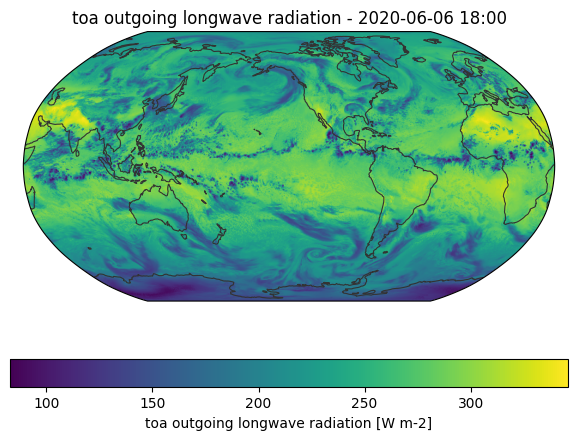

In [13]:
plot_worldmap(dataset, var= "rlut", cmap="viridis")

In [14]:
vlist = ["tas","rain_tot_rate","tb_11","iwp"]

import sys 
sys.path.append("../tools")
import plots_mapping



from matplotlib.colors import LogNorm

cmaps = ["RdBu_r",plots_mapping.precip_colormap()[0],plots_mapping.tb_colormap(),"Blues"]
norms = [None,plots_mapping.precip_colormap()[1],None,LogNorm(1e-3, 1e1)]


for idx, var in enumerate(vlist):
    plot_worldmap(dataset, var = var , cmap = cmaps[idx])

ModuleNotFoundError: No module named 'plots_mapping'

# ggf plot tropcial belt 
https://easy.gems.dkrz.de/Processing/healpix/limited_area_healpix.html

# resample  (to IMERG Grid)

- in example ICON MCStracking nbook! (did not work)
- https://easy.gems.dkrz.de/Processing/healpix/lonlat_remap.html (worked - below)

In [ ]:
def get_nn_lon_lat_index(nside, lons, lats):
    '''
    uses healpy ang2pix function to create index for which cell belongs in each gridcell
    from https://easy.gems.dkrz.de/Processing/healpix/lonlat_remap.html
    '''
    import numpy as np
    import xarray as xr
    import healpy

    
    lons2, lats2 = np.meshgrid(lons, lats)
    return xr.DataArray(
        healpy.ang2pix(nside, lons2, lats2, nest=True, lonlat=True),
        coords=[("lat", lats), ("lon", lons)],
    )

In [ ]:
# open grid 
imerg_grid = xr.open_dataset("../output/aux/imerg_grid.nc")
lons = imerg_grid.lon.values
lats = imerg_grid.lat.values

# prepare resample
idx = get_nn_lon_lat_index(
    2**zoom, lons, lats)

# idx = get_nn_lon_lat_index(
#     2**zoom, np.linspace(-180, 180, 3600), np.linspace(-30, 30, 640)
# )



# resample
tas_lon_lat = dataset.tas.isel(time = 0,cell=idx)
tb_lon_lat = dataset.tb_11.isel(time=0, cell=idx)
precip_lon_lat = dataset.rain_tot_rate.isel(time = 0 , cell = idx)
iwp_lon_lat = dataset.iwp.isel(time = 0, cell = idx)

In [ ]:
tb_lon_lat

In [ ]:
# def resample_to_lon_lat(dataset, variable, itime,zoom = 8, to_imerg = True, lats = None, lons = None, ): 
#     if to_imerg is True: 
#         # open grid 
#         imerg_grid = xr.open_dataset("../output/aux/imerg_grid.nc")
#         lons = imerg_grid.lon.values
#         lats = imerg_grid.lat.values
#         # prepare resample
#         idx = get_nn_lon_lat_index(
#             2**zoom, lons, lats)
              
#     else: 
#         idx = get_nn_lon_lat_index(
#             #2**zoom, np.linspace(-180, 180, 3600), np.linspace(-30, 30, 640)
#             2**zoom, lons, lats)
#     lon_lat = dataset[variable].isel(time=itime, cell=idx)
#     return lon_lat

# # resample
# tas_lon_lat = resample_to_lon_lat(dataset, "tas", itime= 7, to_imerg = True)


In [ ]:
tas_lon_lat

# Plot resampled data

In [ ]:
import plots_mapping
import seaborn as sns
sns.set_context("poster")

fig = plt.figure(figsize=(20, 10))

plots_mapping.plot_tb_map_simple_fast(tb_lon_lat, plots_mapping.tb_colormap(), subplot_shape=(3,1,1),draw_bottom_label=False, fig=fig)
plots_mapping.plot_precip_map_simple_fast(precip_lon_lat, cmap= plots_mapping.precip_colormap(), subplot_shape=(3,1,2), draw_top_label= False,draw_bottom_label=False,fig = fig)
plots_mapping.plot_iwp_map_simple_fast(iwp_lon_lat,subplot_shape=(3, 1, 3),draw_top_label=False,fig=fig)

date = pd.to_datetime(dataset.time[itime].values).strftime("%Y-%m-%d %H:%M")

fig.suptitle(f"ICON Simulation - {date}",fontweight='bold', x=0.5)
        

In [ ]:
import plots_mapping
# plots_mapping.summarized_plot(tb = tb_lon_lat,precip =precip_lon_lat ,iwp= iwp_lon_lat,title= f"ICON Simulation - {date}")        